In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from functions.new_variables import *
from functions.ensembles import *
from scipy.stats import skew, shapiro

In [2]:
# Configure pandas display options to show all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

In [3]:
dataset = pd.read_excel('../../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../../Codificação variaveis.xlsx')

In [4]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
relevant_variables = ['PERSON_ID', 'EBC', 'Survival days', 'Regional LN recurrence', 'Date of 1st regional recurrence']
numerical_variables = ['Age', 'Ki67 positive cells (%) at CB']
categorical_variables = ['Grade at CB', 'Side location of the lesion',
                         'Type of invasion at CB', 'Isotype at CB', 
                         'Oestrogen receptor status at CB', 'Progesterone receptor status at CB', 
                         'Her2 overexpression (with immunohystochemistry) at CB', 
                         'N (Regional nodes affected)']
                         
date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node',
                'Date of intervention (axilla)']

In [5]:
#correcting th error in the column name
dataset.rename(columns={'Istotype at CB': 'Isotype at CB'}, inplace=True)

## Recurrence types

In [61]:
# if 'Distant metastases' in dataset.columns:
#     dataset['Distant metastases'] = dataset['Distant metastases'].fillna(0)

In [62]:
'''import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'dataset' is already loaded in your environment
df = dataset 

death_col = 'Patient status at follow-up'

# Check if primary death column exists
if death_col not in df.columns:
    print(f"Error: Primary status column '{death_col}' not found.")
else:
    # Flag is True if status == 4 (dead)
    death_flag = df[death_col].eq(4)

    comparison_vars = ['Local recurrence', 'Regional LN recurrence', 'Distant metastases']
    available_vars = [col for col in comparison_vars if col in df.columns]

    if not available_vars:
        print("None of the requested variables were found in the dataframe.")
    else:
        summaries = []
        
        # Define what indicates "having" the variable in your dataset. 
        # Modify this list if your data uses different markers (e.g., just [1]).
        positive_values = [1, '1', 'Yes', 'yes', True]

        for var in available_vars:
            # Filter for patients who actually HAVE this specific recurrence
            has_condition = df[var].isin(positive_values)
            
            # Get the death outcomes for only this subset of patients
            deaths_in_subset = death_flag[has_condition]
            
            # Calculate stats
            summary = {
                'Recurrence Type': var,
                'Death Probability': deaths_in_subset.mean(),
                'Deaths': deaths_in_subset.sum(),
                'Total Patients (N)': len(deaths_in_subset)
            }
            summaries.append(summary)

        # Generate the focused comparison table
        comparison_table = pd.DataFrame(summaries)
        display(comparison_table)

        # Plotting the side-by-side comparison
        plt.figure(figsize=(8, 5))
        plt.bar(comparison_table['Recurrence Type'], comparison_table['Death Probability'], color='darkred')
        
        plt.title('Probability of Death (If Patient Has the Recurrence)')
        plt.xlabel('Recurrence Type')
        plt.ylabel('P(death)')
        plt.ylim(0, 1.1)  # Leave room for text labels

        # Add percentage labels on top of the bars
        for i, p in enumerate(comparison_table['Death Probability']):
            if pd.notna(p):  # Ensure there's a valid number to plot
                plt.text(i, p + 0.02, f'{p:.2f}', ha='center', fontweight='bold')

        plt.tight_layout()
        plt.show()'''

'import pandas as pd\nimport matplotlib.pyplot as plt\n\n# Assuming \'dataset\' is already loaded in your environment\ndf = dataset \n\ndeath_col = \'Patient status at follow-up\'\n\n# Check if primary death column exists\nif death_col not in df.columns:\n    print(f"Error: Primary status column \'{death_col}\' not found.")\nelse:\n    # Flag is True if status == 4 (dead)\n    death_flag = df[death_col].eq(4)\n\n    comparison_vars = [\'Local recurrence\', \'Regional LN recurrence\', \'Distant metastases\']\n    available_vars = [col for col in comparison_vars if col in df.columns]\n\n    if not available_vars:\n        print("None of the requested variables were found in the dataframe.")\n    else:\n        summaries = []\n\n        # Define what indicates "having" the variable in your dataset. \n        # Modify this list if your data uses different markers (e.g., just [1]).\n        positive_values = [1, \'1\', \'Yes\', \'yes\', True]\n\n        for var in available_vars:\n         

In [63]:
'''# Define recurrence types
recurrence_cols = ['Local recurrence', 'Regional LN recurrence', 'Distant metastases']

# Filter patients with local recurrence
recurrence = dataset

# Create comparison combinations
combinations = [
    ('Local + Regional', ['Local recurrence', 'Regional LN recurrence']),
    ('Local + Distant', ['Local recurrence', 'Distant metastases']),
    ('Regional + Distant', ['Regional LN recurrence', 'Distant metastases']),
    ('All 3', ['Local recurrence', 'Regional LN recurrence', 'Distant metastases'])
]

summaries = []

for combo_name, cols in combinations:
    # Filter for patients with local recurrence who also have this combination
    mask = (recurrence[cols[0]].isin(positive_values))
    for col in cols[1:]:
        mask = mask & (recurrence[col].isin(positive_values))
    
    subset = recurrence[mask]
    count = len(subset)
    percentage = (count / len(recurrence)) * 100
    
    summaries.append({
        'Combination': combo_name,
        'Count': count,
        'Percentage (of Local Recurrence)': f'{percentage:.2f}%'
    })

comparison_df = pd.DataFrame(summaries)
display(comparison_df)

# Plot comparison
plt.figure(figsize=(10, 6))
plt.bar(comparison_df['Combination'], comparison_df['Count'], color='steelblue')
plt.title('Recurrence Combinations in Patients with Local Recurrence')
plt.xlabel('Recurrence Combination')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()'''

"# Define recurrence types\nrecurrence_cols = ['Local recurrence', 'Regional LN recurrence', 'Distant metastases']\n\n# Filter patients with local recurrence\nrecurrence = dataset\n\n# Create comparison combinations\ncombinations = [\n    ('Local + Regional', ['Local recurrence', 'Regional LN recurrence']),\n    ('Local + Distant', ['Local recurrence', 'Distant metastases']),\n    ('Regional + Distant', ['Regional LN recurrence', 'Distant metastases']),\n    ('All 3', ['Local recurrence', 'Regional LN recurrence', 'Distant metastases'])\n]\n\nsummaries = []\n\nfor combo_name, cols in combinations:\n    # Filter for patients with local recurrence who also have this combination\n    mask = (recurrence[cols[0]].isin(positive_values))\n    for col in cols[1:]:\n        mask = mask & (recurrence[col].isin(positive_values))\n\n    subset = recurrence[mask]\n    count = len(subset)\n    percentage = (count / len(recurrence)) * 100\n\n    summaries.append({\n        'Combination': combo_name,\

In [64]:
'''# Check which recurrence happened first among patients with common recurrences
date_cols = {
    'Local recurrence': 'Date of local recurrence',
    'Regional LN recurrence': 'Date of 1st regional recurrence',
    'Distant metastases': 'Date of 1st distant metastases'
}

# Ensure date columns are datetime
for col in date_cols.values():
    if col in dataset.columns:
        dataset[col] = pd.to_datetime(dataset[col], errors='coerce')

common_combinations = {
    'Local + Regional': ['Local recurrence', 'Regional LN recurrence'],
    'Local + Distant': ['Local recurrence', 'Distant metastases'],
    'Regional + Distant': ['Regional LN recurrence', 'Distant metastases'],
    'All 3': ['Local recurrence', 'Regional LN recurrence', 'Distant metastases']
}

results = []

for combo_name, cols in common_combinations.items():
    mask = np.ones(len(dataset), dtype=bool)
    for col in cols:
        mask &= dataset[col].isin(positive_values)

    subset = dataset.loc[mask, cols + list(date_cols.values())].copy()

    first_counts = {col: 0 for col in cols}
    first_counts['Tie/Simultaneous'] = 0
    first_counts['Missing dates'] = 0

    for _, row in subset.iterrows():
        dates = {rec: row[date_cols[rec]] for rec in cols if pd.notna(row[date_cols[rec]])}

        if len(dates) == 0:
            first_counts['Missing dates'] += 1
            continue

        min_date = min(dates.values())
        winners = [rec for rec, d in dates.items() if d == min_date]

        if len(winners) == 1:
            first_counts[winners[0]] += 1
        else:
            first_counts['Tie/Simultaneous'] += 1

    total = len(subset)
    for key, count in first_counts.items():
        results.append({
            'Combination': combo_name,
            'First recurrence': key,
            'Count': count,
            'Percentage': (count / total * 100) if total > 0 else 0,
        })

first_recurrence_df = pd.DataFrame(results)
display(first_recurrence_df)

# Plot only the first recurrence types (excluding missing dates)
plot_df = first_recurrence_df[first_recurrence_df['First recurrence'].isin(list(date_cols.keys()) + ['Tie/Simultaneous'])]

# Pivot so each combination becomes a separate column for grouped bars
pivot = plot_df.pivot_table(index='First recurrence', columns='Combination', values='Count', aggfunc='sum').fillna(0)

# Ensure a sensible ordering of recurrence types on the x-axis
order = list(date_cols.keys()) + ['Tie/Simultaneous']
pivot = pivot.reindex(order).fillna(0)

ax = pivot.plot(kind='bar', figsize=(12, 6), rot=30, colormap='tab10')
ax.set_title('Which recurrence happened first among common recurrence combinations')
ax.set_xlabel('First recurrence type')
ax.set_ylabel('Number of patients')
ax.legend(title='Combination', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Annotate each bar with its count
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{int(height)}", (p.get_x() + p.get_width() / 2, height),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

plt.show()'''

'# Check which recurrence happened first among patients with common recurrences\ndate_cols = {\n    \'Local recurrence\': \'Date of local recurrence\',\n    \'Regional LN recurrence\': \'Date of 1st regional recurrence\',\n    \'Distant metastases\': \'Date of 1st distant metastases\'\n}\n\n# Ensure date columns are datetime\nfor col in date_cols.values():\n    if col in dataset.columns:\n        dataset[col] = pd.to_datetime(dataset[col], errors=\'coerce\')\n\ncommon_combinations = {\n    \'Local + Regional\': [\'Local recurrence\', \'Regional LN recurrence\'],\n    \'Local + Distant\': [\'Local recurrence\', \'Distant metastases\'],\n    \'Regional + Distant\': [\'Regional LN recurrence\', \'Distant metastases\'],\n    \'All 3\': [\'Local recurrence\', \'Regional LN recurrence\', \'Distant metastases\']\n}\n\nresults = []\n\nfor combo_name, cols in common_combinations.items():\n    mask = np.ones(len(dataset), dtype=bool)\n    for col in cols:\n        mask &= dataset[col].isin(posit

## Continuing

In [6]:
dataset = date_of_diagnosis(dataset, date_columns)

relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
dataset = remove_zeros_na(dataset, relevant_dates)
dataset = format_date(dataset, relevant_dates)

dataset = survival_days(dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
dataset = tte_negative_patients(dataset)
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

In [7]:
# Find duplicated patients
mask = (dataset.duplicated(subset='PERSON_ID', keep=False) & (dataset['Regional LN recurrence'] == 1))

# For each duplicated PERSON_ID with recurrence, keep only the first row
to_remove = (
    dataset[mask]
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

dataset = dataset.drop(to_remove)

## Charts — evidence for the missing-value encoding

The three diagnostic biomarkers ER, PR and HER2 are encoded with an explicit
*missing* level (`one_hot_encode_with_missing_indicator`) instead of being imputed.
The four figures below are the evidence for that choice, in the order the argument runs:

| Figure | Claim |
|---|---|
| 1 | Missingness is **structured**: it lands on the same variables together, in a handful of recurring patterns. (Also shows recurrence rate and median follow-up per pattern — informative, not a formal outcome claim; see the note below the figure.) |
| 2 | Those co-occurrences are **near-deterministic** — every pairwise $\varphi$ sits at its attainable ceiling, so the pattern is one latent event, not noise. |
| 3 | Missingness depends on an **observed** covariate (year of diagnosis), so the mechanism is demonstrably **not MCAR**. This rules out naive imputation, which would treat the missing patients as a random draw from the cohort — they aren't. It does *not* by itself prove the flag is an independently prognostic signal: year of diagnosis isn't otherwise a covariate anywhere in this model, so part of what the flag captures is plausibly administrative (documentation practice, protocol changes) rather than purely biological. Held explicitly rather than papered over. |
| 4 | The group the indicator creates was **diagnosed in a different era** — median year of diagnosis 2018 vs 2014, the one comparison not confounded with a clinical variable (nodal status, grade) that might just track the same trend. |

Recurrence-free survival across the groups does not differ at conventional
significance once follow-up is accounted for (log-rank p ≈ 0.77, 33 events split
across the four pattern-groups in Fig. 1 — badly underpowered). That's reported as
a checked, honest null alongside Fig. 1's event-rate numbers, not as a separate
claim in the chain above.

In [8]:
# ---------------------------------------------------------------------------
# Shared setup for the missingness figures.
#
# Palette: light chart surface, one categorical hue per series (assigned in fixed
# order, never cycled), a single-hue ordinal ramp for ordered levels (N0..N3,
# G1..G3), and a blue-grey-red diverging map for the signed phi heatmap. Colours
# were checked with a CVD/contrast validator; the aqua and yellow slots fall below
# 3:1 on this surface, which is why the line chart carries direct end-of-line
# labels rather than relying on the legend alone.
# ---------------------------------------------------------------------------
from itertools import combinations
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

# Text and structural chart lines (spines, whiskers, reference lines) render in
# pure black. GRID (gridlines) and MUTED (a neutral fill for non-highlighted bars)
# stay a soft grey -- they are backdrop, not something meant to be read as text.
INK, INK_2, MUTED = '#000000', '#000000', '#898781'
GRID, AXIS, SURFACE = '#e1e0d9', '#000000', '#ffffff'
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
# Ordinal ramp starts at step 250, not 100, so the lightest step still clears 2:1
# against the surface when the figure is printed.
RAMP = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans', 'Arial'],
    'font.size': 10, 'text.color': INK, 'axes.labelcolor': INK_2,
    'axes.edgecolor': AXIS, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
})

# The seven pathology / IHC fields that carry essentially all of the missingness.
# Defined here rather than reused from `numerical_variables` / `categorical_variables`
# so the figures do not depend on how far down the notebook has been run.
PATH_COLS = {
    'Ki67 positive cells (%) at CB': 'Ki67',
    'Her2 overexpression (with immunohystochemistry) at CB': 'HER2',
    'Progesterone receptor status at CB': 'PR',
    'Grade at CB': 'Grade',
    'Isotype at CB': 'Isotype',
    'Type of invasion at CB': 'Type of invasion',
    'Oestrogen receptor status at CB': 'ER',
}
ER_COL = 'Oestrogen receptor status at CB'
PR_COL = 'Progesterone receptor status at CB'
H2_COL = 'Her2 overexpression (with immunohystochemistry) at CB'
TIME_COL, EVENT_COL = 'Survival days', 'Regional LN recurrence'


N_PATIENTS = len(dataset)
missing_flags = dataset[list(PATH_COLS)].isna()
missing_flags.columns = list(PATH_COLS.values())

# Groups induced by the encoder: it adds a missing level to ER, PR and HER2, so the
# groups it can actually distinguish are 'all three recorded', 'some recorded' and
# 'none recorded'.
GORDER = ['Panel recorded', 'Partly missing', 'Panel missing']
GCOL = {'Panel recorded': BLUE, 'Partly missing': AQUA, 'Panel missing': ORANGE}


def panel_groups():
    pat = dataset[[ER_COL, PR_COL, H2_COL]].isna().apply(
        lambda r: ''.join('1' if v else '0' for v in r), axis=1)
    g = pd.Series('Panel recorded', index=dataset.index)
    g[(pat != '000') & (pat != '111')] = 'Partly missing'
    g[pat == '111'] = 'Panel missing'
    return g


def save_fig(fig, name):
    """PNG for the notebook, PDF for the thesis (vector text survives scaling)."""
    for ext in ('png', 'pdf'):
        fig.savefig(f'{name}.{ext}', dpi=300, bbox_inches='tight')


print(f'n = {N_PATIENTS:,} patients;  {int(dataset[EVENT_COL].sum())} regional-recurrence events')
print(missing_flags.mean().mul(100).round(2).sort_values(ascending=False).to_string())


n = 3,228 patients;  33 regional-recurrence events
Ki67                16.60
HER2                14.71
PR                  13.79
Grade                6.01
Isotype              4.40
Type of invasion     4.37
ER                   4.21


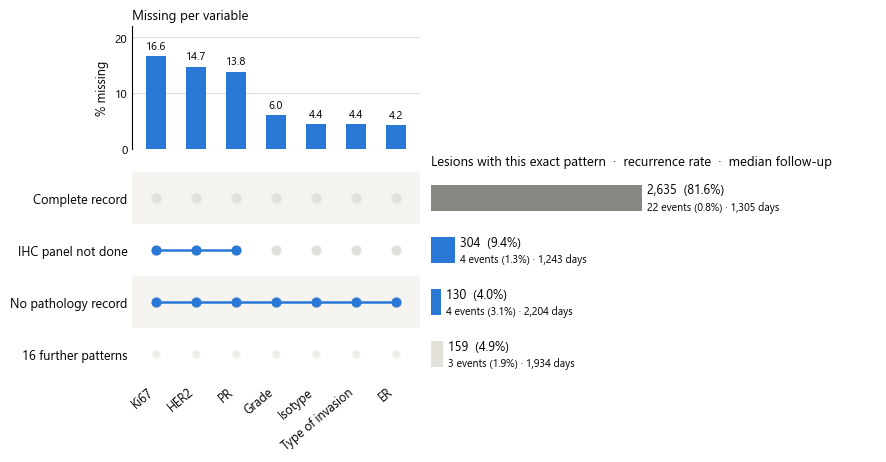

19 distinct patterns; 3 named, covering 95.1%
0000000    2635
1110000     304
1111111     130
1000000      68
0001000      30
1100000      13
0100000      11
0001100       7

Log-rank across these 4 pattern-groups: p = 0.766 (statistic = 1.146, 33 events total) -- underpowered at this event count; treat the rate gradient above as descriptive, not confirmed.


In [9]:
# ---------------------------------------------------------------------------
# Figure 1 - missingness collapses onto a few recurring patterns (UpSet-style).
#
# This replaces the old patient-by-variable raster. At 3,228 patients rendered into
# roughly 2,700 pixels the raster sampled under one pixel per patient, so single-
# patient stripes could be dropped by the renderer and the reader had no way to
# read an exact count off it. A pattern-frequency plot states the counts directly.
#
# Only patterns with a human-readable name below get their own row. A pattern
# where a single field is missing (e.g. "Ki67 only") is a one-off gap, not a
# recurring missingness event, so it is not a category worth naming on its own --
# it folds into "further patterns" together with every other unnamed pattern, no
# matter how large or small. This is an include-list rather than an exclude-list
# so a pattern can never appear as an unlabelled raw binary string.
#
# Each row also carries recurrence rate and median follow-up (Regional LN
# recurrence). This replaces the old standalone Kaplan-Meier chart: shown as plain
# numbers rather than survival curves with confidence bands, since at 33 events
# total the curves' confidence bands were doing more work implying precision than
# the data can support. The log-rank test across these same four groups is printed
# below the figure, not charted -- it is null (underpowered), which is the honest
# result and is not hidden.
# ---------------------------------------------------------------------------
from lifelines.statistics import multivariate_logrank_test

order = list(PATH_COLS.values())
pattern_key = missing_flags.apply(lambda r: ''.join('1' if v else '0' for v in r), axis=1)
pattern_counts = pattern_key.value_counts()

names = {
    '0000000': 'Complete record',
    '1110000': 'IHC panel not done',
    '1111111': 'No pathology record',
}
top = pattern_counts[pattern_counts.index.isin(names)]
rest_n = int(pattern_counts.drop(top.index).sum())
rest_k = int(len(pattern_counts) - len(top))

rows = [(k, int(v), names[k]) for k, v in top.items()]
rows.append((None, rest_n, f'{rest_k} further patterns'))

# Recurrence rate and median follow-up per row, using the same grouping as the
# rows above (the "further patterns" row pools 16 heterogeneous patterns, exactly
# as it already does for the patient count).
group_label = pd.Series('further', index=dataset.index)
for k, v in names.items():
    group_label[pattern_key == k] = v
row_stats = {}
for k, _, label in rows:
    # match on the pattern key, not the display label -- the bucket row's label
    # (e.g. "16 further patterns") includes a dynamic count and never equals the
    # literal 'further' placeholder used to build group_label
    mask = group_label == (names[k] if k is not None else 'further')
    sub = dataset.loc[mask, [TIME_COL, EVENT_COL]].dropna()
    row_stats[label] = dict(events=int(sub[EVENT_COL].sum()), rate=sub[EVENT_COL].mean() * 100,
                            fu=sub[TIME_COL].median())
logrank = multivariate_logrank_test(dataset[TIME_COL], group_label, dataset[EVENT_COL])

fig = plt.figure(figsize=(9.6, 4.6))
gs = GridSpec(2, 2, width_ratios=[1.0, 1.55], height_ratios=[1, 1.7],
              hspace=0.14, wspace=0.03, figure=fig)
ax_top = fig.add_subplot(gs[0, 0])
ax_mat = fig.add_subplot(gs[1, 0], sharex=ax_top)
ax_bar = fig.add_subplot(gs[1, 1], sharey=ax_mat)

x = np.arange(len(order))
pct = (missing_flags.mean() * 100)[order].values
ax_top.bar(x, pct, width=0.5, color=BLUE, zorder=3)
for xi, p in zip(x, pct):
    ax_top.text(xi, p + 0.8, f'{p:.1f}', ha='center', va='bottom', fontsize=8, color=INK_2)
ax_top.set_ylim(0, 22)
ax_top.set_yticks([0, 10, 20])
ax_top.set_ylabel('% missing', fontsize=9, color=INK_2)
ax_top.grid(axis='y', color=GRID, lw=0.8, zorder=0)
ax_top.set_axisbelow(True)
for s in ('top', 'right', 'bottom'):
    ax_top.spines[s].set_visible(False)
ax_top.tick_params(axis='x', length=0, labelbottom=False)
ax_top.tick_params(axis='y', length=0, labelsize=8.5)
ax_top.set_title('Missing per variable', fontsize=9.5, loc='left', color=INK_2, pad=5)

y = np.arange(len(rows))
for yi in y:
    if yi % 2 == 0:
        ax_mat.axhspan(yi - 0.5, yi + 0.5, color='#f4f3ef', zorder=0, lw=0)
for yi, (k, _, _) in enumerate(rows):
    if k is None:
        ax_mat.plot(x, [yi] * len(x), ls='', marker='o', ms=5, color='#efeee9', zorder=2)
        continue
    on = [i for i, c in enumerate(k) if c == '1']
    off = [i for i, c in enumerate(k) if c == '0']
    ax_mat.scatter(off, [yi] * len(off), s=54, color=GRID, zorder=2, lw=0)
    if on:
        ax_mat.plot([min(on), max(on)], [yi, yi], color=BLUE, lw=1.8, zorder=2)
        ax_mat.scatter(on, [yi] * len(on), s=54, color=BLUE, zorder=3, lw=0)
ax_mat.set_xticks(x)
ax_mat.set_xticklabels(order, rotation=40, ha='right', fontsize=9)
ax_mat.set_xlim(-0.6, len(order) - 0.4)
ax_mat.set_yticks(y)
ax_mat.set_yticklabels([r[2] for r in rows], fontsize=9.2)
ax_mat.set_ylim(len(rows) - 0.5, -0.5)
ax_mat.tick_params(axis='both', length=0)
for s in ax_mat.spines.values():
    s.set_visible(False)

counts = [r[1] for r in rows]
colors = [MUTED if r[0] == '0' * 7 else (GRID if r[0] is None else BLUE) for r in rows]
ax_bar.barh(y, counts, height=0.5, color=colors, zorder=3)
for yi, (c, r) in enumerate(zip(counts, rows)):
    rs = row_stats[r[2]]
    ax_bar.text(c + N_PATIENTS * 0.018, yi - 0.15, f'{c:,}  ({c / N_PATIENTS * 100:.1f}%)',
                va='center', fontsize=9, color=INK)
    ax_bar.text(c + N_PATIENTS * 0.018, yi + 0.17,
                f'{rs["events"]} events ({rs["rate"]:.1f}%) \u00b7 {rs["fu"]:,.0f} days',
                va='center', fontsize=7.6, color=INK_2)
ax_bar.set_xlim(0, N_PATIENTS * 1.72)
ax_bar.set_xticks([])
# sharey would otherwise repeat the pattern names inside the bar panel
ax_bar.tick_params(axis='y', length=0, labelleft=False)
for s in ax_bar.spines.values():
    s.set_visible(False)
ax_bar.set_title('Lesions with this exact pattern  \u00b7  recurrence rate  \u00b7  median follow-up',
                 fontsize=9.5, loc='left', color=INK_2, pad=5)

save_fig(fig, 'fig1_missingness_patterns')
plt.show()

print(f'{len(pattern_counts)} distinct patterns; {len(top)} named, covering '
      f'{top.sum() / N_PATIENTS * 100:.1f}%')
print(pattern_counts.head(8).to_string())
print()
print(f'Log-rank across these 4 pattern-groups: p = {logrank.p_value:.3f} '
      f'(statistic = {logrank.test_statistic:.3f}, {int(dataset[EVENT_COL].sum())} events total) '
      f'-- underpowered at this event count; treat the rate gradient above as descriptive, not confirmed.')


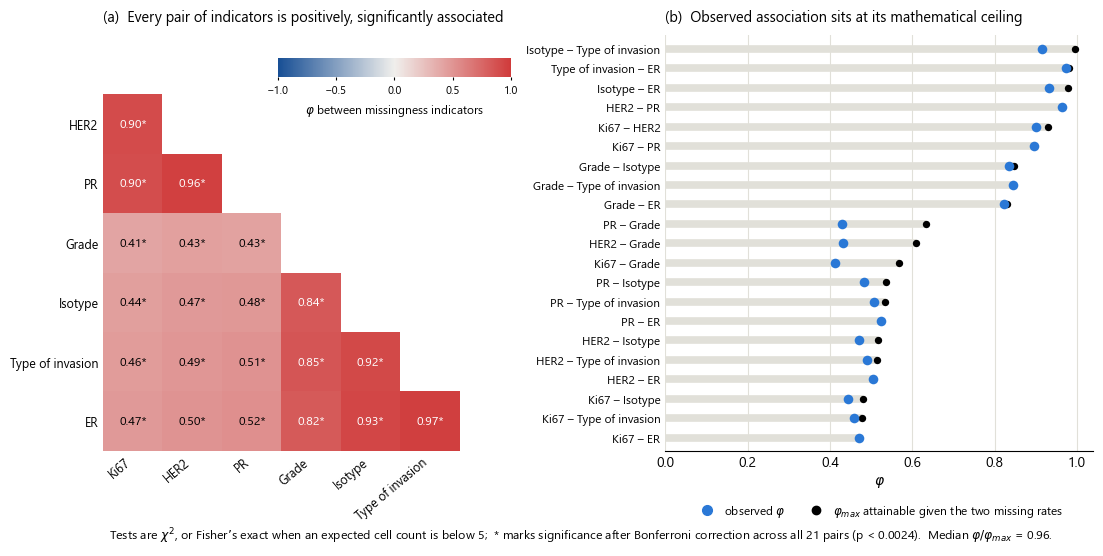

,a,b,phi,phi_max,ratio,test,p,sig
0,Type of invasion,ER,0.974,0.981,0.992,Chi-square,0.00e+00,True
1,HER2,PR,0.963,0.963,1.000,Chi-square,0.00e+00,True
2,Isotype,ER,0.933,0.978,0.954,Chi-square,0.00e+00,True
3,Isotype,Type of invasion,0.915,0.996,0.918,Chi-square,0.00e+00,True
4,Ki67,HER2,0.900,0.931,0.967,Chi-square,0.00e+00,True
5,Ki67,PR,0.896,0.896,1.000,Chi-square,0.00e+00,True
6,Grade,Type of invasion,0.845,0.845,1.000,Chi-square,0.00e+00,True
7,Grade,Isotype,0.836,0.848,0.985,Chi-square,0.00e+00,True
8,Grade,ER,0.823,0.829,0.992,Chi-square,0.00e+00,True
9,PR,ER,0.524,0.524,1.000,Chi-square,4.10e-195,True


In [51]:
# ---------------------------------------------------------------------------
# Figure 2 - the indicators are mutually near-deterministic.
#
# (a) raw phi, lower triangle only (the diagonal and mirror carry no information).
# (b) phi against phi_max. phi between two binary variables is capped by their
#     marginal rates through the Frechet-Hoeffding bounds on the joint probability:
#     with p1 = P(X missing) and p2 = P(Y missing), P(both) can only range over
#     [max(0, p1+p2-1), min(p1, p2)]. Plotting the observed value against that
#     ceiling shows how much of the attainable association is actually realised.
#
# This replaces the old normalised-phi heatmap, which had two problems: it was
# computed over variables missing for under 0.5% of patients, where the ceiling
# collapses toward zero and the ratio is pushed to +-1 by a handful of records; and
# every surviving cell rendered as the same saturated red, so the panel conveyed
# nothing visually. Restricting to the seven pathology fields (4-17% missing each)
# keeps every bound numerically stable.
# ---------------------------------------------------------------------------
from scipy.stats import chi2_contingency, fisher_exact

cols = list(PATH_COLS.values())
pairs = list(combinations(cols, 2))
bonf_alpha = 0.05 / len(pairs)


def phi_ceiling(p1, p2):
    lo, hi = sorted([p1, p2])
    return np.sqrt((lo * (1 - hi)) / (hi * (1 - lo)))


records = []
for a, b in pairs:
    c1, c2 = missing_flags[a], missing_flags[b]
    phi = c1.astype(int).corr(c2.astype(int))
    table = pd.crosstab(c1, c2).reindex(index=[False, True], columns=[False, True], fill_value=0)
    _, _, _, expected = chi2_contingency(table, correction=False)
    if (expected < 5).any():
        _, p = fisher_exact(table)
        test = "Fisher's exact"
    else:
        _, p, _, _ = chi2_contingency(table, correction=False)
        test = 'Chi-square'
    pmax = phi_ceiling(c1.mean(), c2.mean())
    records.append(dict(a=a, b=b, phi=phi, phi_max=pmax, ratio=phi / pmax,
                        test=test, p=p, sig=p < bonf_alpha))
missingness_tests = pd.DataFrame(records)

phi_m = pd.DataFrame(np.nan, index=cols, columns=cols)
sig_m = pd.DataFrame(False, index=cols, columns=cols)
for _, r in missingness_tests.iterrows():
    phi_m.loc[r.a, r.b] = phi_m.loc[r.b, r.a] = r.phi
    sig_m.loc[r.a, r.b] = sig_m.loc[r.b, r.a] = r.sig

diverging = LinearSegmentedColormap.from_list('bwr', ['#184f95', '#f0efec', '#d03b3b'])
fig = plt.figure(figsize=(12.8, 5.4))
gs = GridSpec(1, 2, width_ratios=[1, 1.02], wspace=0.34, figure=fig)
axL, axR = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])

m = phi_m.loc[cols, cols].to_numpy(float)
mask = np.triu(np.ones_like(m, dtype=bool))
im = axL.imshow(np.ma.masked_where(mask, m), cmap=diverging, vmin=-1, vmax=1)
for i in range(len(cols)):
    for j in range(len(cols)):
        if mask[i, j]:
            continue
        v = m[i, j]
        axL.text(j, i, f'{v:.2f}' + ('*' if sig_m.iloc[i, j] else ''), ha='center',
                 va='center', fontsize=8.8, color=SURFACE if abs(v) > 0.55 else INK)
axL.set_xticks(np.arange(len(cols) - 1))
axL.set_xticklabels(cols[:-1], rotation=40, ha='right', fontsize=9)
axL.set_yticks(np.arange(1, len(cols)))
axL.set_yticklabels(cols[1:], fontsize=9)
axL.tick_params(length=0)
for s in axL.spines.values():
    s.set_visible(False)
# the masked upper triangle is free space - put the scale there
cax = axL.inset_axes([0.42, 0.90, 0.56, 0.045])
cb = fig.colorbar(im, cax=cax, orientation='horizontal')
cb.set_label('$\\varphi$ between missingness indicators', fontsize=8.6, color=INK_2, labelpad=4)
cb.ax.tick_params(labelsize=8, length=2, color=AXIS)
cb.outline.set_visible(False)
axL.set_title('(a)  Every pair of indicators is positively, significantly associated',
              fontsize=10.5, loc='left', pad=10, color=INK)

r = missingness_tests.sort_values('phi_max').reset_index(drop=True)
yy = np.arange(len(r))
axR.hlines(yy, 0, r.phi_max, color=GRID, lw=5.5, zorder=1)
axR.scatter(r.phi_max, yy, s=28, color=AXIS, zorder=2, lw=0)
axR.scatter(r.phi, yy, s=48, color=BLUE, zorder=3, lw=0)
axR.set_yticks(yy)
axR.set_yticklabels([f'{a} \u2013 {b}' for a, b in zip(r.a, r.b)], fontsize=8.5)
axR.set_ylim(-0.7, len(r) - 0.3)
axR.set_xlim(0, 1.04)
axR.set_xlabel('$\\varphi$', fontsize=10)
axR.grid(axis='x', color=GRID, lw=0.8, zorder=0)
axR.set_axisbelow(True)
axR.tick_params(length=0)
for s in ('top', 'right', 'left'):
    axR.spines[s].set_visible(False)
axR.set_title('(b)  Observed association sits at its mathematical ceiling',
              fontsize=10.5, loc='left', pad=10, color=INK)
axR.legend(handles=[
    Line2D([], [], marker='o', ls='', color=BLUE, markersize=7, label='observed $\\varphi$'),
    Line2D([], [], marker='o', ls='', color=AXIS, markersize=6,
           label='$\\varphi_{max}$ attainable given the two missing rates')],
    loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=False,
    fontsize=8.6, handletextpad=0.4, columnspacing=1.6)

fig.text(0.5, -0.055,
         f'Tests are $\\chi^2$, or Fisher\u2019s exact when an expected cell count is below 5;  '
         f'* marks significance after Bonferroni correction across all {len(pairs)} pairs '
         f'(p < {bonf_alpha:.4f}).  Median $\\varphi/\\varphi_{{max}}$ = {r.ratio.median():.2f}.',
         fontsize=8.9, color=INK_2, ha='center')
save_fig(fig, 'fig2_missingness_correlation')
plt.show()

display(missingness_tests.sort_values('phi', ascending=False)
        .round({'phi': 3, 'phi_max': 3, 'ratio': 3})
        .assign(p=lambda d: d['p'].map('{:.2e}'.format))
        .reset_index(drop=True))


4 markers -> Bonferroni-corrected alpha = 0.0125
  ER    point-biserial r = -0.282   p = 3.55e-60   (significant; missing patients diagnosed earlier)
  PR    point-biserial r = -0.147   p = 4.18e-17   (significant; missing patients diagnosed earlier)
  HER2  point-biserial r = -0.154   p = 1.60e-18   (significant; missing patients diagnosed earlier)
  Ki67  point-biserial r = -0.217   p = 9.50e-36   (significant; missing patients diagnosed earlier)

2001-2010 (n = 12, pooled): ER 8, PR 8, HER2 8, Ki67 10


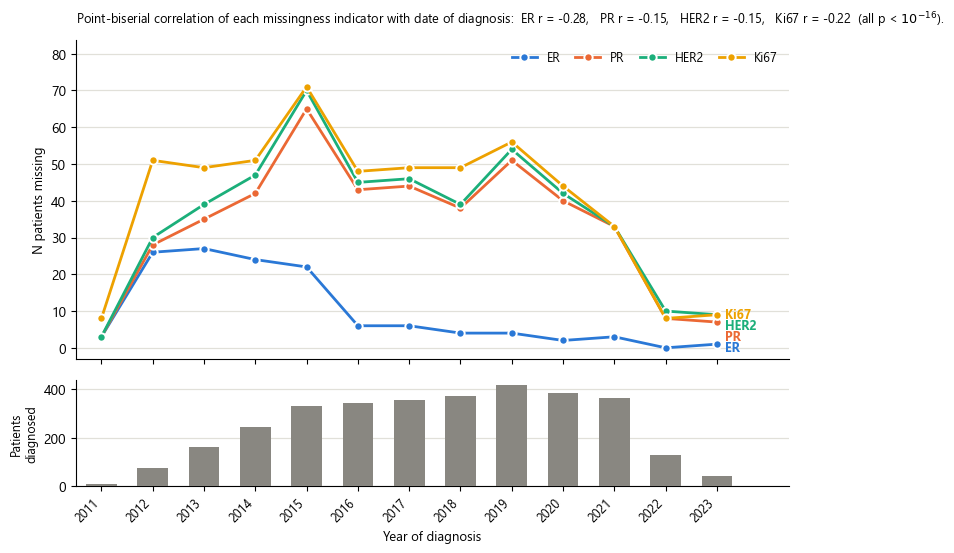

In [55]:
# ---------------------------------------------------------------------------
# Figure 3 - missingness tracks year of diagnosis: rules out MCAR, with a caveat.
#
# Practice around ordering and electronically recording a full core-biopsy IHC
# panel changed over the ~22 years the cohort spans, so missingness is partly
# explained by *when* a patient was diagnosed -- an observed variable. That rules
# out MCAR (which requires missingness to be independent of everything) -- the
# missing values cannot be treated as exchangeable with the observed ones, so an
# unconditional mean/mode fill would be quietly asserting these patients look like
# a random draw from the whole cohort, when the data says they don't.
#
# That is what this figure proves, and no more. It does NOT by itself show the
# missing flag is an independently prognostic signal, or that it is "about" the
# biomarker rather than about the era. Year of diagnosis is not otherwise a
# covariate anywhere in this model, so part of what the flag captures is plausibly
# administrative (protocol changes, follow-up-window differences) rather than
# biological. Flagging rather than imputing is still the right call -- asserting a
# specific value we have positive reason to doubt is worse than being honest it's
# unknown -- but that is a narrower, more defensible claim than "the flag is
# causally clean," which this figure does not establish.
#
# The same time-dependence holds, more strongly, across all seven pathology
# fields checked (printed below), not just the four IHC-panel markers plotted --
# consistent with a broad, cohort-wide documentation-practice shift rather than
# something specific to these particular biomarkers.
#
# Shown as raw counts rather than rates: the earliest years have very few patients
# (2011, n=11), so their missingness rate is dramatic (Ki67 72.7%) but not
# informative -- a handful of patients swings a percentage wildly, and a rate chart
# hides where the missing-indicator encoding actually has to carry the most
# patients. The trend-over-time claim itself is carried by the point-biserial
# correlation below, computed per patient, so it does not depend on how the chart
# bins or displays the data.
# ---------------------------------------------------------------------------
from scipy.stats import pointbiserialr

all_fields = {ER_COL: 'ER', PR_COL: 'PR', H2_COL: 'HER2', 'Ki67 positive cells (%) at CB': 'Ki67',
             'Grade at CB': 'Grade', 'Isotype at CB': 'Isotype',
             'Type of invasion at CB': 'Type of invasion'}
markers = {ER_COL: 'ER', PR_COL: 'PR', H2_COL: 'HER2', 'Ki67 positive cells (%) at CB': 'Ki67'}
marker_colors = {'ER': BLUE, 'PR': ORANGE, 'HER2': AQUA, 'Ki67': YELLOW}

# 'Date of diagnosis' holds python date objects at this point; convert locally
# without mutating `dataset`.
diagnosis_dt = pd.to_datetime(dataset['Date of diagnosis'])
diagnosis_year = diagnosis_dt.dt.year
date_ordinal = diagnosis_dt.map(pd.Timestamp.toordinal)

bonf_year = 0.05 / len(all_fields)
print(f'{len(all_fields)} pathology fields -> Bonferroni-corrected alpha = {bonf_year:.4f}')
field_stats = {}
for col, nm in all_fields.items():
    rr, pp = pointbiserialr(dataset[col].isna().astype(int), date_ordinal)
    field_stats[nm] = (rr, pp)
    flag = 'significant' if pp < bonf_year else 'n.s.'
    note = '' if nm in markers.values() else '  (not plotted below)'
    print(f'  {nm:16s} point-biserial r = {rr:+.3f}   p = {pp:.2e}   ({flag}; missing patients diagnosed earlier){note}')
marker_stats = {nm: field_stats[nm] for nm in markers.values()}

# 2001-2010 holds only a dozen patients - far too sparse for a per-year count, so it
# is reported as one pooled figure instead of plotted.
trend = diagnosis_year >= 2011
counts_by_year = pd.DataFrame({nm: dataset.loc[trend, c].isna() for c, nm in markers.items()}
                              ).groupby(diagnosis_year[trend]).sum().astype(int)
n_by_year = diagnosis_year[trend].value_counts().sort_index()
pre_2011 = dataset.loc[diagnosis_year < 2011, list(markers)]
pre_2011_counts = pre_2011.isna().sum()
pre_2011_counts.index = [markers[c] for c in pre_2011_counts.index]
print(f'\n2001-2010 (n = {len(pre_2011)}, pooled): '
      + ', '.join(f'{nm} {int(n)}' for nm, n in pre_2011_counts.items()))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.2, 5.8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.10})
yrs = counts_by_year.index.to_numpy()
for nm, c in marker_colors.items():
    ax1.plot(yrs, counts_by_year[nm], color=c, lw=2, marker='o', ms=6, markerfacecolor=c,
             markeredgecolor=SURFACE, markeredgewidth=1.4, label=nm, zorder=3)

# End-of-line direct labels: aqua and yellow sit below 3:1 against the surface, so
# the palette's relief rule wants visible labels rather than legend-only identity.
ends = sorted(((counts_by_year[nm].iloc[-1], nm) for nm in marker_colors), reverse=True)
placed, min_gap = [], 3.0
for val, nm in ends:
    placed.append((val if not placed else min(val, placed[-1][0] - min_gap), nm))
for yv, nm in placed:
    ax1.annotate(nm, xy=(yrs[-1] + 0.16, yv), va='center', ha='left', fontsize=9,
                 color=marker_colors[nm], fontweight='bold')

ax1.set_ylabel('N patients missing', fontsize=9.5)
ax1.set_ylim(-3, counts_by_year.to_numpy().max() * 1.18)
ax1.set_xlim(yrs[0] - 0.5, yrs[-1] + 1.4)
ax1.grid(axis='y', color=GRID, lw=0.9, zorder=0)
ax1.set_axisbelow(True)
for s in ('top', 'right'):
    ax1.spines[s].set_visible(False)
ax1.legend(loc='upper right', frameon=False, fontsize=9, ncol=4, columnspacing=1.2)
summary = ',   '.join(f'{nm} r = {marker_stats[nm][0]:+.2f}' for nm in marker_colors)
ax1.text(0.0, 1.035, f'Point-biserial correlation of each missingness indicator with date of '
                     f'diagnosis:  {summary}  (all p < $10^{{-16}}$).',
         transform=ax1.transAxes, fontsize=9.2, color=INK_2, va='bottom')

ax2.bar(yrs, n_by_year.values, color=MUTED, width=0.6, zorder=3)
ax2.set_ylabel('Patients\ndiagnosed', fontsize=9)
ax2.set_xlabel('Year of diagnosis', fontsize=9.5)
ax2.set_xticks(yrs)
ax2.set_xticklabels(yrs, rotation=45, ha='right', fontsize=9)
ax2.grid(axis='y', color=GRID, lw=0.9, zorder=0)
ax2.set_axisbelow(True)
for s in ('top', 'right'):
    ax2.spines[s].set_visible(False)

save_fig(fig, 'fig3_missingness_by_year')
plt.show()


group sizes: {'Panel recorded': 2753, 'Partly missing': 339, 'Panel missing': 136}
Year of diagnosis: Kruskal-Wallis p = 1.204e-40;  medians = {'Panel recorded': 2018.0, 'Partly missing': 2018.0, 'Panel missing': 2014.0}


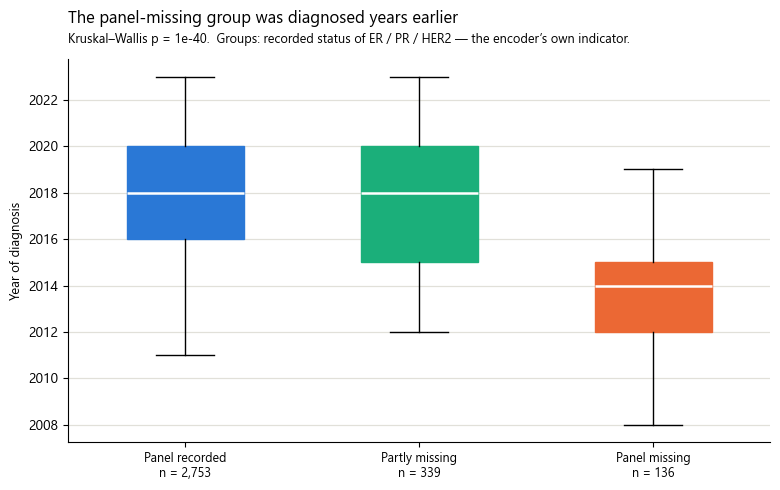


Negative controls:
  Age              KW p = 0.096
  Side location  chi2 p = 0.069


In [53]:
# ---------------------------------------------------------------------------
# Figure 4 - the group the indicator creates was diagnosed in a different era.
#
# Dropped from the original draft: nodal status and tumour grade. Both are
# themselves clinical variables that could just as easily track the same year-of-
# diagnosis trend as the missingness itself (staging and grading practice also
# changed over the 22-year span) rather than add anything the missingness
# indicator doesn't already carry -- showing them risked mistaking two things that
# both move with era for independent evidence, when it may just be coincidence.
# Follow-up duration is dropped too: given a fixed data-cutoff date, an earlier
# diagnosis mechanically implies a longer follow-up, so it repeats (a) rather than
# adding to it.
#
# What's left is the one comparison that isn't open to that objection: year of
# diagnosis is not a proxy for something else, it *is* the era -- computed here at
# the group level the encoder actually creates (rather than per-marker, as in
# Figure 3), so the two figures make distinct claims rather than repeating one.
# ---------------------------------------------------------------------------
from scipy.stats import kruskal, chi2_contingency

groups = panel_groups()
gsize = {k: int((groups == k).sum()) for k in GORDER}
gds = dataset.assign(_g=groups)
gds['_year'] = pd.to_datetime(gds['Date of diagnosis']).dt.year

year_data = [gds.loc[gds._g == k, '_year'].dropna().values for k in GORDER]
p_year = kruskal(*year_data).pvalue
medians = {k: float(np.median(v)) for k, v in zip(GORDER, year_data)}
print('group sizes:', gsize)
print(f'Year of diagnosis: Kruskal-Wallis p = {p_year:.3e};  medians = {medians}')

fig, ax = plt.subplots(figsize=(7.9, 5.0))
bp = ax.boxplot(year_data, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=SURFACE, lw=1.8),
                whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for patch, k in zip(bp['boxes'], GORDER):
    patch.set_facecolor(GCOL[k]); patch.set_edgecolor(GCOL[k])
ax.set_xticks(range(1, 4))
ax.set_xticklabels([f'{k}\nn = {gsize[k]:,}' for k in GORDER], fontsize=9)
ax.set_ylabel('Year of diagnosis', fontsize=9.5)
ax.grid(axis='y', color=GRID, lw=0.9, zorder=0)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.set_title('The panel-missing group was diagnosed years earlier',
             fontsize=12, loc='left', pad=26, color=INK)
ax.text(0.0, 1.035,
        f'Kruskal\u2013Wallis p = {p_year:.0e}.  Groups: recorded status of ER / PR / HER2 \u2014 the '
        f'encoder\u2019s own indicator.',
        transform=ax.transAxes, fontsize=9.2, color=INK_2, va='bottom')
plt.tight_layout()
save_fig(fig, 'fig4_group_differences')
plt.show()

# Negative controls: age and laterality have no reason to track era, and don't --
# the year-of-diagnosis gap isn't a stand-in for every variable being noisier in
# one group, it's specific to when the panel was ordered.
print('\nNegative controls:')
print('  Age              KW p = %.3f' % kruskal(*[gds.loc[gds._g == k, 'Age'].dropna() for k in GORDER]).pvalue)
_side = pd.crosstab(gds._g, gds['Side location of the lesion'])
print('  Side location  chi2 p = %.3f' % chi2_contingency(_side).pvalue)


## Continuing

In [ ]:
# pT(dataset)
# cT (dataset)
# clinical_staging(dataset)
# didn't place the ct in the new variables, the pt is already at the top
# new_variables = ['Cancer stage']
# categorical_variables = categorical_variables + new_variables

In [ ]:
change_to_numeric(dataset, numerical_variables)
change_to_categorical(dataset, categorical_variables)

Done
Done


In [ ]:
'''# Find duplicated patients with recurrence = 1
mask = dataset.duplicated(subset='PERSON_ID', keep=False) & dataset['Regional LN recurrence'].eq(1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True], na_position='last')
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

# Find duplicated patients with recurrence = 0
mask = dataset.duplicated(subset='PERSON_ID', keep=False) & dataset['Regional LN recurrence'].eq(0)

# For each duplicated PERSON_ID, keep only the row with the highest survival days
to_remove_2 = (
    dataset[mask]
    .index
)

# Get rows with Regional LN recurrence = 0
recurrence_df = dataset[dataset['Regional LN recurrence'].eq(0)]

# Find duplicated PERSON_IDs
duplicated_ids = (
    recurrence_df[recurrence_df.duplicated(subset='PERSON_ID', keep=False)]['PERSON_ID']
    .dropna()
    .unique()
)

# For each duplicated PERSON_ID, show the differences
for person_id in duplicated_ids:
    person_rows = recurrence_df[recurrence_df['PERSON_ID'] == person_id]
    print(f"\nPERSON_ID: {person_id}")

    diff_cols = []
    for col in person_rows.columns:
        if person_rows[col].nunique(dropna=False) > 1:
            diff_cols.append(col)

    if diff_cols:
        print(f"Columns with differences: {diff_cols}")
        print(person_rows[['PERSON_ID'] + diff_cols])
    else:
        print("No differences found between rows")'''

'# Find duplicated patients with recurrence = 1\nmask = dataset.duplicated(subset=\'PERSON_ID\', keep=False) & dataset[\'Regional LN recurrence\'].eq(1)\n\n# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days\nto_remove = (\n    dataset[mask]\n    .sort_values([\'PERSON_ID\', \'Survival days\'], ascending=[True, True], na_position=\'last\')\n    .groupby(\'PERSON_ID\')\n    .head(-1)\n    .index\n)\n\n# Find duplicated patients with recurrence = 0\nmask = dataset.duplicated(subset=\'PERSON_ID\', keep=False) & dataset[\'Regional LN recurrence\'].eq(0)\n\n# For each duplicated PERSON_ID, keep only the row with the highest survival days\nto_remove_2 = (\n    dataset[mask]\n    .index\n)\n\n# Get rows with Regional LN recurrence = 0\nrecurrence_df = dataset[dataset[\'Regional LN recurrence\'].eq(0)]\n\n# Find duplicated PERSON_IDs\nduplicated_ids = (\n    recurrence_df[recurrence_df.duplicated(subset=\'PERSON_ID\', keep=False)][\'PERSON_ID\']\n  

In [ ]:
columns_to_map = {
    'Side location of the lesion': {'L': 0, 'R': 1},
    'Type of invasion at CB': {1: 0, 2: 1},
    'Oestrogen receptor status at CB': {1: 0, 2: 1},
    'Progesterone receptor status at CB': {1: 0, 2: 1},
    'N (Regional nodes affected)': {0: 0, 1: 1, 2: 2_3, 3: 2_3}
    }

for column, mapping in columns_to_map.items():
    dataset[column] = dataset[column].map(mapping)

In [ ]:
# Replace missing values with 0 (not the mode)
# dataset['Isotype at CB'] = dataset['Isotype at CB'].fillna(0)

# 'cT', 'Cancer stage', 'Classification with respect to other lesions', 'Disease extent'
mode_variables = ['Grade at CB', 'Side location of the lesion', 'N (Regional nodes affected)', 'Type of invasion at CB', 'Isotype at CB']
fill_with_mode(dataset, mode_variables)

'Done'

In [ ]:
# it actually makes a difference
handle_missing = ['Oestrogen receptor status at CB', 'Her2 overexpression (with immunohystochemistry) at CB', 'Progesterone receptor status at CB']
#posso meter aqui tbm outros como o disease e retirar o isotype, vai dar tudo ao mesmo kinda
dataset, new_columns = one_hot_encode_with_missing_indicator(dataset, handle_missing)
categorical_variables = [col for col in categorical_variables if col not in handle_missing]
categorical_variables.extend(new_columns)

In [ ]:
median = ['Ki67 positive cells (%) at CB']
median_imputer(dataset, numerical_variables)

'Done'

In [ ]:
# removi o'cT', 'Cancer stage', e o Classification with respect to other lesions e o Disease extent
one_hot_variables = ['Grade at CB', 'N (Regional nodes affected)', 'Isotype at CB']
ohe_dataset, new_column_names = one_hot_encoding(dataset, one_hot_variables, drop_first='first')

In [ ]:
categorical_variables = [col for col in categorical_variables if col not in one_hot_variables]
categorical_variables.extend(new_column_names.tolist())

selected_variables = relevant_variables + numerical_variables + categorical_variables

In [ ]:
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Endocrine therapy performed']
                        # 'Date of first administration of biological drugs for adjuvant therapy', 'Final recommendations to patient']
selected_variables_treat = selected_variables + treatment_variables

survival_dataset = ohe_dataset[selected_variables_treat].copy()

Now the treatment variables, just because it was already made

In [ ]:
dataset = survival_dataset

In [ ]:
numerical_data, categorical_data = type_separation(data_code, treatment_variables)
len(numerical_data), len(categorical_data)

(3, 10)

In [ ]:
replace_missing_values(dataset, numerical_data, 0)

Done


In [ ]:
# dataset.drop(index=0, inplace=True) removed the drop of the patient
dataset.reset_index(inplace=True, drop=True)
replace_missing_values(dataset, categorical_data, 0)

Done


In [ ]:
'''# Snapshot these three variables before 'two_to_zero' recodes 'Chemotherapy performed' (2 -> 0),
# so later comparisons can use the original encodings (missing values already filled with 0 above).
pre_two_to_zero_snapshot = dataset[[
    'State (if hormone therapy prescribed)',
    'Chemotherapy performed',
    'Treatment in association with chemotherapy',
]].copy()'''

In [ ]:
variable_two_to_zero = ['Adjuvant chemotherapy', 'Chemotherapy performed', 'Endocrine therapy performed']
two_to_zero(dataset, variable_two_to_zero)

bio_variable = 'Adjuvant therapy with biological drugs'
dataset = encode_bio_therapy(dataset, bio_variable)

In [ ]:
feature_columns = ['Adjuvant therapy using biological drugs'] #, 'Trastuzumab or other drugs']
feature_columns = feature_columns + categorical_data + numerical_data

treatment_variables = [col for col in feature_columns if col not in bio_variable]

In [ ]:
# Create a derived neojuven therapy only variable.
# It is 1 when adjuvant therapy with biological drugs is 0 and endocrine therapy performed is 1.

dataset['Neoadjuvant (Only) therapy with biological drugs'] = (
    (dataset['Adjuvant therapy using biological drugs'] == 0) &
    (dataset['Endocrine therapy performed'] == 1)
).astype(int)

treatment_variables = [
    col for col in treatment_variables
    if col != 'Endocrine therapy performed'
]
treatment_variables.append('Neoadjuvant (Only) therapy with biological drugs')

In [ ]:
to_remove = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']
important_variables = ['PERSON_ID', 'Regional LN recurrence', 'Survival days']
diagnosis_variables = [col for col in selected_variables if col not in to_remove]
selected_columns = important_variables + treatment_variables + diagnosis_variables

In [ ]:
survival_dataset = dataset[selected_columns]

## adjuvant

In [ ]:
'''# Compare the two treatment variables and count the four possible binary combinations
comparison_cols = ['Adjuvant therapy using biological drugs', 'Endocrine therapy performed']
comparison_df = survival_dataset[comparison_cols].copy()
comparison_df = comparison_df.fillna(0)

contingency = pd.crosstab(
    comparison_df[comparison_cols[0]],
    comparison_df[comparison_cols[1]],
    rownames=[comparison_cols[0]],
    colnames=[comparison_cols[1]],
    dropna=False
)

# Ensure all four binary combinations are shown, even if one is absent
contingency = contingency.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
display(contingency)

summary = pd.DataFrame([
    {'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 1, 'Patients': int(contingency.loc[1, 1])},
    {'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 0, 'Patients': int(contingency.loc[1, 0])},
    {'Adjuvant therapy with biological drugs': 0, 'Endocrine therapy performed': 1, 'Patients': int(contingency.loc[0, 1])},
    {'Adjuvant therapy with biological drugs': 0, 'Endocrine therapy performed': 0, 'Patients': int(contingency.loc[0, 0])},
])
summary['Percentage'] = (summary['Patients'] / len(comparison_df)) * 100
display(summary)

plt.figure(figsize=(7, 4))
labels = ['1 / 1', '1 / 0', '0 / 1', '0 / 0']
counts = [contingency.loc[1, 1], contingency.loc[1, 0], contingency.loc[0, 1], contingency.loc[0, 0]]
bars = plt.bar(labels, counts, color=['darkgreen', 'steelblue', 'darkorange', 'dimgray'])
plt.title('Comparison between treatment variables')
plt.xlabel('Adjuvant therapy with biological drugs / Endocrine therapy performed')
plt.ylabel('Number of patients')

for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()'''

"# Compare the two treatment variables and count the four possible binary combinations\ncomparison_cols = ['Adjuvant therapy using biological drugs', 'Endocrine therapy performed']\ncomparison_df = survival_dataset[comparison_cols].copy()\ncomparison_df = comparison_df.fillna(0)\n\ncontingency = pd.crosstab(\n    comparison_df[comparison_cols[0]],\n    comparison_df[comparison_cols[1]],\n    rownames=[comparison_cols[0]],\n    colnames=[comparison_cols[1]],\n    dropna=False\n)\n\n# Ensure all four binary combinations are shown, even if one is absent\ncontingency = contingency.reindex(index=[0, 1], columns=[0, 1], fill_value=0)\ndisplay(contingency)\n\nsummary = pd.DataFrame([\n    {'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 1, 'Patients': int(contingency.loc[1, 1])},\n    {'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 0, 'Patients': int(contingency.loc[1, 0])},\n    {'Adjuvant therapy with biological drugs': 0, 'Endocrine 

In [ ]:
'''# Compare the two treatment variables against final recommendations separately for values 3 and 4
# The final recommendation variable is split into patients with value 3 and patients with value 4.
# The two treatment variables are already binary.

comparison_vars = ['Adjuvant therapy using biological drugs', 'Endocrine therapy performed']

final_recommendation_numeric = pd.to_numeric(survival_dataset[final_recommendation_col], errors='coerce')

results = []
for recommendation_value in [3, 4]:
    subset = survival_dataset[final_recommendation_numeric == recommendation_value][comparison_vars].copy()
    subset = subset.fillna(0)

    contingency = pd.crosstab(
        subset[comparison_vars[0]],
        subset[comparison_vars[1]],
        rownames=[comparison_vars[0]],
        colnames=[comparison_vars[1]],
        dropna=False,
    )

    contingency = contingency.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    display(contingency)

    summary = pd.DataFrame([
        {'Final recommendations to patient': recommendation_value, 'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 1, 'Patients': int(contingency.loc[1, 1])},
        {'Final recommendations to patient': recommendation_value, 'Adjuvant therapy with biological drugs': 1, 'Endocrine therapy performed': 0, 'Patients': int(contingency.loc[1, 0])},
        {'Final recommendations to patient': recommendation_value, 'Adjuvant therapy with biological drugs': 0, 'Endocrine therapy performed': 1, 'Patients': int(contingency.loc[0, 1])},
        {'Final recommendations to patient': recommendation_value, 'Adjuvant therapy with biological drugs': 0, 'Endocrine therapy performed': 0, 'Patients': int(contingency.loc[0, 0])},
    ])
    summary['Percentage'] = (summary['Patients'] / len(subset)) * 100 if len(subset) > 0 else 0
    display(summary)

    results.append((recommendation_value, contingency))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (recommendation_value, contingency) in zip(axes, results):
    labels = ['1 / 1', '1 / 0', '0 / 1', '0 / 0']
    counts = [contingency.loc[1, 1], contingency.loc[1, 0], contingency.loc[0, 1], contingency.loc[0, 0]]
    bars = ax.bar(labels, counts, color=['darkgreen', 'steelblue', 'darkorange', 'dimgray'])
    ax.set_title(f'Final recommendations to patient = {recommendation_value}')
    ax.set_xlabel('Adjuvant therapy with biological drugs / Endocrine therapy performed')
    ax.set_ylabel('Number of patients')

    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()'''

"# Compare the two treatment variables against final recommendations separately for values 3 and 4\n# The final recommendation variable is split into patients with value 3 and patients with value 4.\n# The two treatment variables are already binary.\n\ncomparison_vars = ['Adjuvant therapy using biological drugs', 'Endocrine therapy performed']\n\nfinal_recommendation_numeric = pd.to_numeric(survival_dataset[final_recommendation_col], errors='coerce')\n\nresults = []\nfor recommendation_value in [3, 4]:\n    subset = survival_dataset[final_recommendation_numeric == recommendation_value][comparison_vars].copy()\n    subset = subset.fillna(0)\n\n    contingency = pd.crosstab(\n        subset[comparison_vars[0]],\n        subset[comparison_vars[1]],\n        rownames=[comparison_vars[0]],\n        colnames=[comparison_vars[1]],\n        dropna=False,\n    )\n\n    contingency = contingency.reindex(index=[0, 1], columns=[0, 1], fill_value=0)\n    display(contingency)\n\n    summary = pd.Dat

In [ ]:
'''# Compare the three binary variables together
# The date variable is treated as 1 when present and 0 when missing.
# The two treatment variables are already binary.

bio_date_col = 'Date of first administration of biological drugs for adjuvant therapy'

all_three_df = dataset[[
    bio_date_col,
    'Adjuvant therapy using biological drugs',
    'Endocrine therapy performed',
]].copy()

all_three_df[bio_date_col] = all_three_df[bio_date_col].notna() & all_three_df[bio_date_col].ne(0)
all_three_df['Adjuvant therapy using biological drugs'] = all_three_df['Adjuvant therapy using biological drugs'].fillna(0).astype(bool)
all_three_df['Endocrine therapy performed'] = all_three_df['Endocrine therapy performed'].fillna(0).astype(bool)

all_three_summary = (
    all_three_df
    .value_counts(sort=False)
    .rename('Patients')
    .reset_index()
)

all_three_summary['Percentage'] = (all_three_summary['Patients'] / len(all_three_df)) * 100
all_three_summary = all_three_summary.rename(columns={
    bio_date_col: 'Date present',
})
display(all_three_summary)

all_three_summary['Combination'] = (
    all_three_summary['Date present'].astype(int).astype(str) + ' / ' +
    all_three_summary['Adjuvant therapy using biological drugs'].astype(int).astype(str) + ' / ' +
    all_three_summary['Endocrine therapy performed'].astype(int).astype(str)
)

all_three_summary = all_three_summary.sort_values('Patients', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(all_three_summary['Combination'], all_three_summary['Patients'], color='slateblue')
plt.title('Comparison of the three binary variables together')
plt.xlabel('Date / Biological therapy / Endocrine therapy')
plt.ylabel('Number of patients')
plt.xticks(rotation=45, ha='right')

for bar, count in zip(bars, all_three_summary['Patients']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()'''

"# Compare the three binary variables together\n# The date variable is treated as 1 when present and 0 when missing.\n# The two treatment variables are already binary.\n\nbio_date_col = 'Date of first administration of biological drugs for adjuvant therapy'\n\nall_three_df = dataset[[\n    bio_date_col,\n    'Adjuvant therapy using biological drugs',\n    'Endocrine therapy performed',\n]].copy()\n\nall_three_df[bio_date_col] = all_three_df[bio_date_col].notna() & all_three_df[bio_date_col].ne(0)\nall_three_df['Adjuvant therapy using biological drugs'] = all_three_df['Adjuvant therapy using biological drugs'].fillna(0).astype(bool)\nall_three_df['Endocrine therapy performed'] = all_three_df['Endocrine therapy performed'].fillna(0).astype(bool)\n\nall_three_summary = (\n    all_three_df\n    .value_counts(sort=False)\n    .rename('Patients')\n    .reset_index()\n)\n\nall_three_summary['Percentage'] = (all_three_summary['Patients'] / len(all_three_df)) * 100\nall_three_summary = all_thre

In [ ]:
'''# Kaplan-Meier curve until recurrence
# The recurrence time variable used throughout the notebook is 'Survival days'.
# Event is 'Regional LN recurrence' == 1.
# Compare adjuvant therapy, neo-adjuvant therapy, and endocrine therapy.

from lifelines import KaplanMeierFitter

def _pick_existing_column(frame, candidates):
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    raise KeyError(f'None of these columns exist: {candidates}')

adjuvant_col = _pick_existing_column(survival_dataset, [
    'Adjuvant therapy with biological drugs',
    'Adjuvant therapy using biological drugs',
])
endocrine_col = 'Endocrine therapy performed'
time_col = 'Survival days'
event_col = 'Regional LN recurrence'

km_df = survival_dataset[[time_col, event_col, adjuvant_col, endocrine_col]].copy()
km_df = km_df.dropna(subset=[time_col, event_col])
km_df[time_col] = pd.to_numeric(km_df[time_col], errors='coerce')
km_df[event_col] = pd.to_numeric(km_df[event_col], errors='coerce').fillna(0).astype(int)
km_df[adjuvant_col] = pd.to_numeric(km_df[adjuvant_col], errors='coerce').fillna(0).astype(int)
km_df[endocrine_col] = pd.to_numeric(km_df[endocrine_col], errors='coerce').fillna(0).astype(int)
km_df = km_df.dropna(subset=[time_col])

adjuvant_mask = km_df[adjuvant_col] == 1
neo_adjuvant_mask = (km_df[endocrine_col] == 1) & (km_df[adjuvant_col] == 0)
endocrine_mask = km_df[endocrine_col] == 1

summary = pd.DataFrame([
    {
        'therapy_group': 'Adjuvant therapy',
        'Patients': int(adjuvant_mask.sum()),
        'Recurrences': int(km_df.loc[adjuvant_mask, event_col].sum()),
    },
    {
        'therapy_group': 'Neo-adjuvant therapy',
        'Patients': int(neo_adjuvant_mask.sum()),
        'Recurrences': int(km_df.loc[neo_adjuvant_mask, event_col].sum()),
    },
    {
        'therapy_group': 'Endocrine therapy',
        'Patients': int(endocrine_mask.sum()),
        'Recurrences': int(km_df.loc[endocrine_mask, event_col].sum()),
    },
])
display(summary)

kmf = KaplanMeierFitter()
plt.figure(figsize=(9, 6))

for group_name, mask in [
    ('Adjuvant therapy', adjuvant_mask),
    ('Neo-adjuvant therapy', neo_adjuvant_mask),
    ('Endocrine therapy', endocrine_mask),
]:
    group_df = km_df.loc[mask]
    if group_df.empty:
        continue
    kmf.fit(
        durations=group_df[time_col],
        event_observed=group_df[event_col],
        label=group_name,
    )
    kmf.plot_survival_function(ci_show=True)

plt.title('Kaplan-Meier curve until recurrence')
plt.xlabel('Time to recurrence (days)')
plt.ylabel('Recurrence-free survival probability')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()'''

"# Kaplan-Meier curve until recurrence\n# The recurrence time variable used throughout the notebook is 'Survival days'.\n# Event is 'Regional LN recurrence' == 1.\n# Compare adjuvant therapy, neo-adjuvant therapy, and endocrine therapy.\n\nfrom lifelines import KaplanMeierFitter\n\ndef _pick_existing_column(frame, candidates):\n    for candidate in candidates:\n        if candidate in frame.columns:\n            return candidate\n    raise KeyError(f'None of these columns exist: {candidates}')\n\nadjuvant_col = _pick_existing_column(survival_dataset, [\n    'Adjuvant therapy with biological drugs',\n    'Adjuvant therapy using biological drugs',\n])\nendocrine_col = 'Endocrine therapy performed'\ntime_col = 'Survival days'\nevent_col = 'Regional LN recurrence'\n\nkm_df = survival_dataset[[time_col, event_col, adjuvant_col, endocrine_col]].copy()\nkm_df = km_df.dropna(subset=[time_col, event_col])\nkm_df[time_col] = pd.to_numeric(km_df[time_col], errors='coerce')\nkm_df[event_col] = pd.

## continuing

In [ ]:
'''# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False) & (survival_dataset['Regional LN recurrence'] == 1))

# For each duplicated PERSON_ID with recurrence, keep only the first row
to_remove = (
    survival_dataset[mask]
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)'''

In [ ]:
# Check if there are any NaN values in the dataset
contains_nan = survival_dataset.isnull().any().any()
print("Does survival_dataset contain NaN values?", contains_nan)

# Optionally, to see which columns contain NaN values
nan_columns = survival_dataset.columns[survival_dataset.isnull().any()].tolist()
print("Columns with NaN values:", nan_columns)

Does survival_dataset contain NaN values? False
Columns with NaN values: []


In [ ]:
# status_4 = survival_dataset[survival_dataset['Patient status at follow-up'] == 4]

# counts = status_4['Regional LN recurrence'].value_counts().reindex([0, 1], fill_value=0)

# print("Patients with Patient status at follow-up = 4:")
# print(f"Regional LN recurrence = 0: {counts[0]}")
# print(f"Regional LN recurrence = 1: {counts[1]}")
# print(f"Total: {len(status_4)}")

In [ ]:
survival_dataset.to_csv("data.csv")

In [ ]:
with open("diagnosis.txt", "w") as file:
    for item in diagnosis_variables:
        file.write(str(item) + "\n")
with open("treatment.txt", "w") as file:
    for item in treatment_variables:
        file.write(str(item) + "\n")

## Hormone therapy / chemotherapy treatment combinations

,Combination,State (if hormone therapy prescribed),Chemotherapy performed,Treatment in association with chemotherapy,Patients,Percentage
0,1 / 0 / 0,1,0,0,1344,41.648590
1,1 / 1 / 1,1,1,1,835,25.875426
2,1 / 0 / 1,1,0,1,399,12.364425
3,0 / 1 / 0,0,1,0,329,10.195228
4,0 / 0 / 0,0,0,0,315,9.761388
5,0 / 2 / 0,0,2,0,4,0.123954
6,1 / 2 / 1,1,2,1,1,0.030989
7,0 / 0 / 1,0,0,1,0,0.000000
8,0 / 1 / 1,0,1,1,0,0.000000
9,0 / 2 / 1,0,2,1,0,0.000000


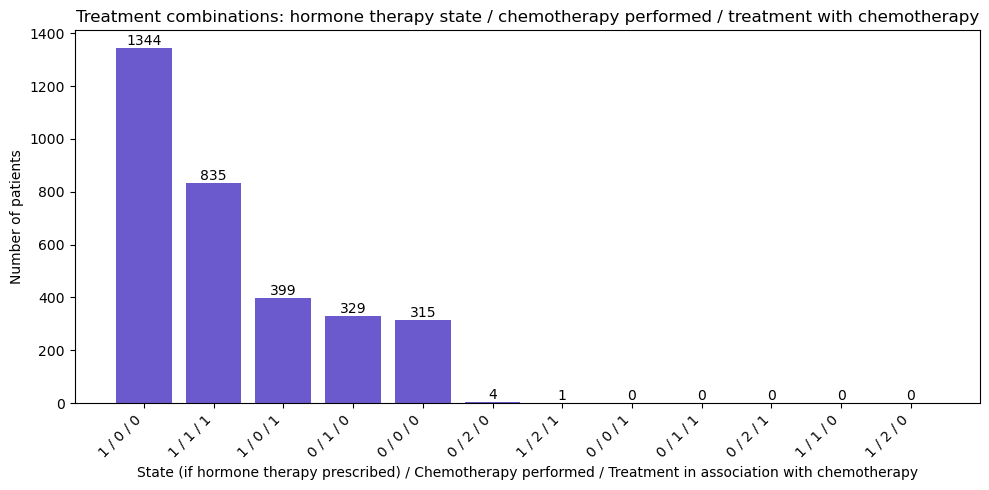

In [ ]:
'''import itertools

# Compare the three treatment variables using their original encodings (i.e. without the
# 'two_to_zero' recoding applied to 'Chemotherapy performed' elsewhere in the notebook).
# Missing values are filled with 0; the raw value 2 (a small group of patients for
# 'Chemotherapy performed') is kept as its own category instead of being folded into 0.
combo_vars = [
    'State (if hormone therapy prescribed)',
    'Chemotherapy performed',
    'Treatment in association with chemotherapy',
]

combo_df = pre_two_to_zero_snapshot.loc[survival_dataset.index, combo_vars].copy()
for col in combo_vars:
    combo_df[col] = pd.to_numeric(combo_df[col], errors='coerce').fillna(0).astype(int)

# Enumerate every combination actually present for each variable (so the 2s show up too)
value_domains = [sorted(combo_df[col].unique()) for col in combo_vars]
all_combinations = pd.MultiIndex.from_tuples(
    list(itertools.product(*value_domains)),
    names=combo_vars,
)

combo_counts = (
    combo_df
    .value_counts()
    .reindex(all_combinations, fill_value=0)
    .rename('Patients')
    .reset_index()
)
combo_counts['Percentage'] = (combo_counts['Patients'] / len(combo_df)) * 100
combo_counts['Combination'] = combo_counts[combo_vars].astype(str).agg(' / '.join, axis=1)
combo_counts = combo_counts.sort_values('Patients', ascending=False).reset_index(drop=True)

display(combo_counts[['Combination'] + combo_vars + ['Patients', 'Percentage']])

plt.figure(figsize=(10, 5))
bars = plt.bar(combo_counts['Combination'], combo_counts['Patients'], color='slateblue')
plt.title('Treatment combinations: hormone therapy state / chemotherapy performed / treatment with chemotherapy')
plt.xlabel('State (if hormone therapy prescribed) / Chemotherapy performed / Treatment in association with chemotherapy')
plt.ylabel('Number of patients')
plt.xticks(rotation=45, ha='right')

for bar, count in zip(bars, combo_counts['Patients']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(count)), ha='center', va='bottom')

plt.tight_layout()
plt.show()'''